# Studenten gaan geld verdienen ..
We gaan een portfolio maken via Yahoo Finance (https://finance.yahoo.com/) en de FED in St. Louis (https://fred.stlouisfed.org/categories).

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

# Aandelen, obligatie en crypto's
Alle libraries geinstalleerd, nu de data:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Portfolio

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
portfolio_gefilterd

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,39.726143,48.679867,269.661926,32.033474,28.472565,63.861736,197.858353,76.212563,9119.009766,0.841407
2018-05-02,41.481045,48.771523,269.609314,31.062515,28.712614,64.452644,195.668015,76.175385,9235.919922,0.859094
2018-05-03,41.556217,49.074661,277.087677,31.350521,28.942226,63.316315,195.132980,76.167976,9743.860352,0.884466
2018-05-04,43.186604,49.236824,275.481445,31.753721,29.025728,64.089020,196.412064,76.264488,9700.759766,0.895442
2018-05-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63755.320312,0.526112
2024-04-27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63419.140625,0.517775
2024-04-28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63113.230469,0.510377


## Schonen van de data

In [ ]:
portfolio_gevuld = portfolio_gefilterd.ffill()
portfolio_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,39.726143,48.679867,269.661926,32.033474,28.472565,63.861736,197.858353,76.212563,9119.009766,0.841407
2018-05-02,41.481045,48.771523,269.609314,31.062515,28.712614,64.452644,195.668015,76.175385,9235.919922,0.859094
2018-05-03,41.556217,49.074661,277.087677,31.350521,28.942226,63.316315,195.132980,76.167976,9743.860352,0.884466
2018-05-04,43.186604,49.236824,275.481445,31.753721,29.025728,64.089020,196.412064,76.264488,9700.759766,0.895442
2018-05-05,43.186604,49.236824,275.481445,31.753721,29.025728,64.089020,196.412064,76.264488,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63755.320312,0.526112
2024-04-27,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63419.140625,0.517775
2024-04-28,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63113.230469,0.510377


Bereken nu ook de dagrendementen:

In [ ]:
portfolio_dag = portfolio_gevuld.pct_change()
portfolio_dag = portfolio_dag.dropna()
portfolio_dag

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-02,0.044175,0.001883,-0.000195,-0.030311,0.008431,0.009253,-0.011070,-0.000488,0.012820,0.021021
2018-05-03,0.001812,0.006215,0.027738,0.009272,0.007997,-0.017630,-0.002734,-0.000097,0.054996,0.029533
2018-05-04,0.039233,0.003304,-0.005797,0.012861,0.002885,0.012204,0.006555,0.001267,-0.004423,0.012410
2018-05-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.016225,0.010789
2018-05-06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.020628,-0.037210
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,-0.003473,0.000000,-0.015592,0.012593,0.006787,0.006759,0.017903,0.000449,-0.011265,0.001142
2024-04-27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.005273,-0.015846
2024-04-28,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.004824,-0.014288


## Statistiek

In [ ]:
portfolio_dag.describe()

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
count,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000,2191.000000
mean,0.000796,0.000308,0.000357,0.000818,0.000484,0.000647,0.000466,0.000030,0.001472,0.001225
std,0.016462,0.018239,0.014412,0.018210,0.016787,0.021381,0.016436,0.002953,0.034586,0.055510
min,-0.128647,-0.171722,-0.101463,-0.140341,-0.094237,-0.151592,-0.127053,-0.041856,-0.371695,-0.423340
25%,-0.003596,-0.004019,-0.003593,-0.004803,-0.003990,-0.006394,-0.004567,-0.000570,-0.013053,-0.020439
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000786,-0.000566
75%,0.006500,0.005372,0.004778,0.006892,0.006500,0.006641,0.005509,0.000971,0.016041,0.018970
max,0.119808,0.196795,0.130012,0.126522,0.157880,0.147299,0.175803,0.019994,0.187465,0.730750


Conclusie?

## Grafieken
Even kijken hoe het eruit ziet (zonder de coins, die vertekenen het plaatje nogal ..):

Text(0.5, 1.0, 'Slotkoersen Portfolio')

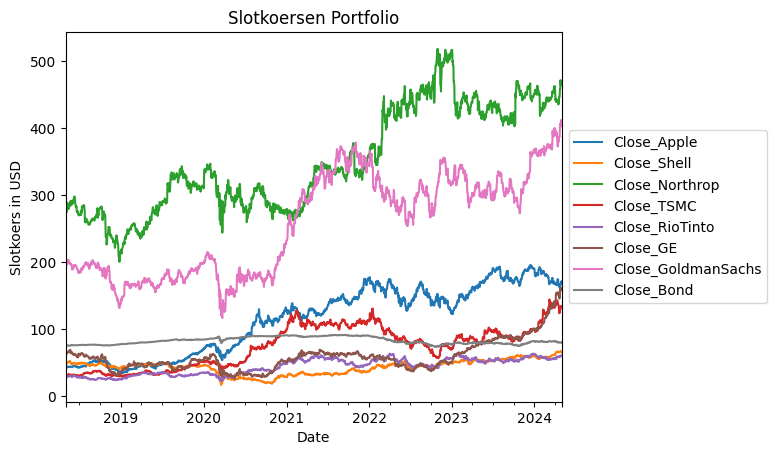

In [ ]:
portfolio_plaatje = portfolio_gevuld.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC", "Close_RioTinto", "Close_GE", "Close_GoldmanSachs", "Close_Bond"]]
portfolio_plaatje.plot()
plt.ylabel("Slotkoers in USD") # y-as naam geven
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.title("Slotkoersen Portfolio") # Grafiek een naam geven

Conclusie?

### Histogram

array([[<Axes: title={'center': 'Close_Apple'}>,
        <Axes: title={'center': 'Close_Shell'}>,
        <Axes: title={'center': 'Close_Northrop'}>,
        <Axes: title={'center': 'Close_TSMC'}>],
       [<Axes: title={'center': 'Close_RioTinto'}>,
        <Axes: title={'center': 'Close_GE'}>,
        <Axes: title={'center': 'Close_GoldmanSachs'}>,
        <Axes: title={'center': 'Close_Bond'}>],
       [<Axes: title={'center': 'Close_Bitcoin'}>,
        <Axes: title={'center': 'Close_Ripple'}>, <Axes: >, <Axes: >]],
      dtype=object)

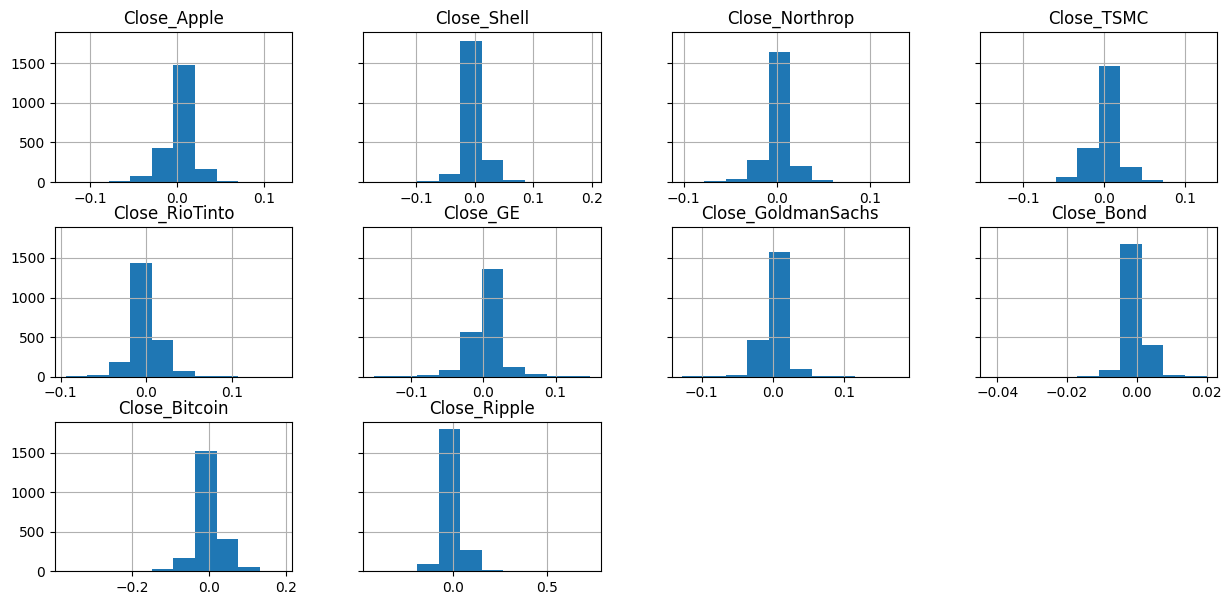

In [ ]:
portfolio_dag.hist(layout=(3, 4), figsize=(15, 7), sharey=True)

### Skewness (of scheefheid)
Geeft aan of de verdeling symmetrisch, links- of rechtsscheef is.
<p>
Als skewness = 0: verdeling is symmetrisch<br>
Als skewness < 0: verdeling is linksscheef, de staarten aan de linkerkant zijn groter / langer dan bij een symmetrische verdeling<br>
Als skewness > 0: verdeling is rechtsscheef, de staarten aan de rechterkant zijn groter / langer dan bij een symmetrische verdeling<br>
<p>
Zie ook: skewness (wikipedia): https://en.wikipedia.org/wiki/Skewness
<p>
In python te berekenen via het commando skew():

In [ ]:
portfolio_dag.skew()

,0
Close_Apple,0.029391
Close_Shell,-0.447330
Close_Northrop,0.228907
Close_TSMC,0.479017
Close_RioTinto,0.407486
Close_GE,0.202571
Close_GoldmanSachs,0.291757
Close_Bond,-1.796024
Close_Bitcoin,-0.356062
Close_Ripple,2.325059


Conclusie?

### Kurtosis
Geeft aan of de verdeling 'spits' (met veel uitschieters) of 'vlak' (met weinig uitschieters) is.
<p>
Als kurtosis = 0: verdeling is symmetrisch<br>
Als kurtosis =< 3: verdeling heeft weinig uitschieters<br>
Als kurtosis > 3: verdeling heeft veel uitschieters<br>
<p>
Zie ook: kurtosis (wikipedia): https://en.wikipedia.org/wiki/Kurtosis
<p>
In python te berekenen via het commando kurtosis():

In [ ]:
import scipy.stats as stats
from scipy.stats import kurtosis

# Calculate kurtosis for all columns
kurtosis_values = portfolio_dag.apply(lambda x: kurtosis(x, nan_policy='omit'))

# Display the results
print(kurtosis_values)

Close_Apple            8.662367
Close_Shell           22.050185
Close_Northrop        12.764263
Close_TSMC             6.723471
Close_RioTinto         8.518663
Close_GE               7.998256
Close_GoldmanSachs    16.224720
Close_Bond            30.210820
Close_Bitcoin          9.146133
Close_Ripple          28.371360
dtype: float64


Conclusie?

### Boxplot

<Axes: >

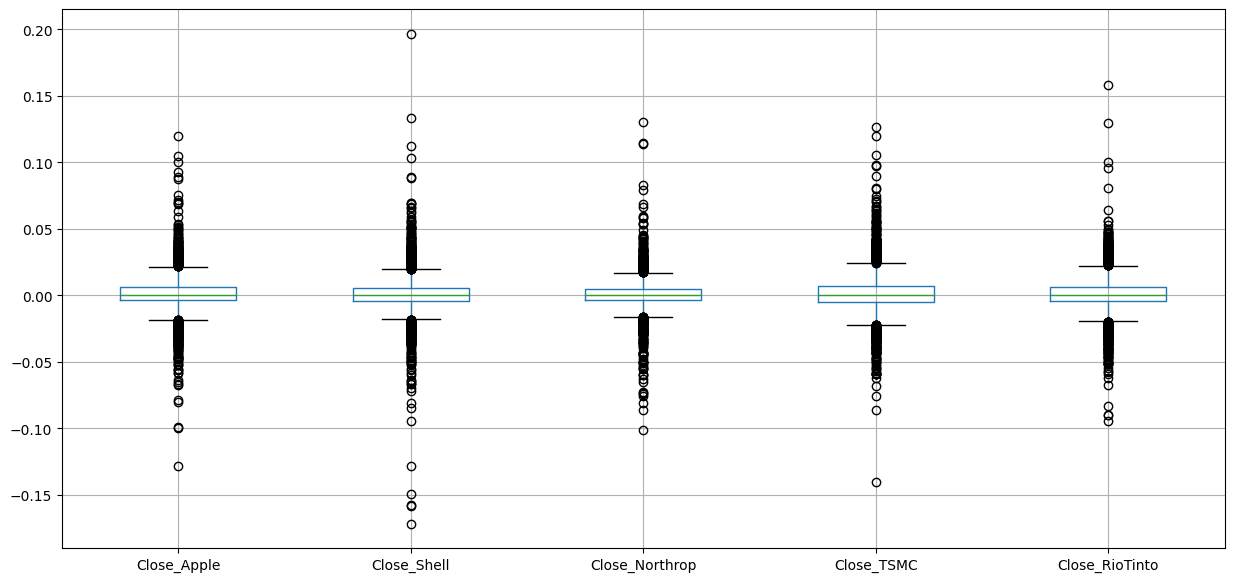

In [ ]:
portfolio_dag.boxplot(column=["Close_Apple", "Close_Shell","Close_Northrop","Close_TSMC","Close_RioTinto"], figsize=(15, 7))

Conclusie?

# Grondstoffen
https://tradingeconomics.com/commodities

In [ ]:
graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

#kobalt
#silicium

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Sowieso toe te voegen aan deze tabellen: is dit een prijs per dag? In welke eenheid? Per m3 of liter of vat of ..

## Portfolio

In [ ]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]
grondstoffen_1

,Graan,Koffie,Vlees,Gas,Kolen
DATE,,,,,
2018-05-01,192.70383,194.200,188.000000,NaN,595.400
2018-05-07,NaN,NaN,NaN,2.845,NaN
2018-05-14,NaN,NaN,NaN,2.873,NaN
2018-05-21,NaN,NaN,NaN,2.923,NaN
2018-05-28,NaN,NaN,NaN,2.962,NaN
...,...,...,...,...,...
2024-04-08,NaN,NaN,NaN,3.591,NaN
2024-04-15,NaN,NaN,NaN,3.628,NaN
2024-04-22,NaN,NaN,NaN,3.668,NaN


In [ ]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]
grondstoffen_2

,Olie,Goud,Palladium
Date,,,
2018-05-01,67.250000,1303.800049,938.450012
2018-05-02,67.930000,1302.599976,962.349976
2018-05-03,68.430000,1310.699951,960.900024
2018-05-04,69.720001,1312.699951,959.450012
2018-05-07,70.730003,1312.199951,964.299988
...,...,...,...
2024-04-24,82.809998,2324.500000,1007.400024
2024-04-25,83.570000,2329.800049,981.099976
2024-04-26,83.849998,2334.800049,957.400024


In [ ]:
grondstoffen_portfolio = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_portfolio

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.70383,194.200,188.000000,NaN,595.400,67.250000,1303.800049,938.450012
2018-05-02,NaN,NaN,NaN,NaN,NaN,67.930000,1302.599976,962.349976
2018-05-03,NaN,NaN,NaN,NaN,NaN,68.430000,1310.699951,960.900024
2018-05-04,NaN,NaN,NaN,NaN,NaN,69.720001,1312.699951,959.450012
2018-05-07,NaN,NaN,NaN,2.845,NaN,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2024-04-25,NaN,NaN,NaN,NaN,NaN,83.570000,2329.800049,981.099976
2024-04-26,NaN,NaN,NaN,NaN,NaN,83.849998,2334.800049,957.400024
2024-04-29,NaN,NaN,NaN,3.653,NaN,82.629997,2345.399902,976.700012
2024-04-30,NaN,NaN,NaN,NaN,NaN,81.930000,2291.399902,951.900024


## Schonen van de data
We zien dat lang niet alle dagen gevuld zijn. Hoe komt dat?<br>
- sommige grondstoffen hebben 1x per maand een waarde (prijs)<br>
- sommige grondstoffen hebben 1x per week een waarde<br>
- sommige grondstoffen hebben 1x per dag een waarde<br>

Hoe lossen we dit op?<br>
Een mogelijkheid is om alle week- en maanddata op te vullen (= forward fillen) totdat alle dagen gevuld zijn:

In [ ]:
grondstoffen_gevuld = grondstoffen_portfolio.ffill()
grondstoffen_gevuld

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


We zijn nu bijna waar we wezen willen: alle rijen en kolommen gevuld.<br>
Laatste schoonmaakactie: het verwijderen / filteren van alle overgebleven NaN's.<p>
Dit doen we door als startdatum een datum te kiezen waarbij voor ALLE grondstoffen prijzen per dag aanwezig zijn.
We zoeken eerst deze datum:

In [ ]:
grondstoffen_compleet = grondstoffen_gevuld.loc[grondstoffen_gevuld.loc[:, "Gas"] > 0, :]
grondstoffen_compleet

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


De datum die we zoeken is 7 mei 2018. Deze datum kunnen we nu gebruiken als startdatum voor onze grondstofportfolio.

In [ ]:
grondstoffen_compleet_dag = grondstoffen_compleet.pct_change()
grondstoffen_compleet_dag = grondstoffen_compleet_dag.dropna()
grondstoffen_compleet_dag

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-08,0.000000,0.000000,0.000000,0.000000,0.000000,-0.023611,-0.000152,0.001348
2018-05-09,0.000000,0.000000,0.000000,0.000000,0.000000,0.030119,-0.000533,0.007457
2018-05-10,0.000000,0.000000,0.000000,0.000000,0.000000,0.003093,0.007245,0.023951
2018-05-11,0.000000,0.000000,0.000000,0.000000,0.000000,-0.009249,-0.001363,-0.008734
2018-05-14,0.000000,0.000000,0.000000,0.009842,0.000000,0.003678,-0.001895,0.010634
...,...,...,...,...,...,...,...,...
2024-04-25,0.000000,0.000000,0.000000,0.000000,0.000000,0.009178,0.002280,-0.026107
2024-04-26,0.000000,0.000000,0.000000,0.000000,0.000000,0.003350,0.002146,-0.024157
2024-04-29,0.000000,0.000000,0.000000,-0.004089,0.000000,-0.014550,0.004540,0.020159
2024-04-30,0.000000,0.000000,0.000000,0.000000,0.000000,-0.008471,-0.023024,-0.025392


## Statistiek

In [ ]:
grondstoffen_compleet.describe()

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
count,1561.000000,1561.000000,1561.000000,1561.000000,1561.000000,1561.000000,1561.000000,1561.000000
mean,241.458888,212.729089,221.125508,3.034900,693.913192,67.714388,1708.088595,1758.890199
std,72.363382,23.436957,28.348012,0.655257,200.861762,19.218970,268.617559,546.011694
min,146.570486,193.400000,168.369565,1.773000,415.700000,-37.630001,1176.199951,845.200012
25%,178.241777,194.300000,199.304348,2.561000,562.500000,55.590000,1499.099976,1276.300049
50%,219.238068,197.400000,215.727273,2.961000,630.300000,69.169998,1784.099976,1786.800049
75%,299.440006,239.662000,246.977273,3.487000,833.238000,79.489998,1906.099976,2213.399902
max,444.156568,256.609000,275.304348,5.006000,1196.186000,123.699997,2398.399902,2985.399902


In [ ]:
grondstoffen_compleet_dag.describe()

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
count,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000
mean,0.000211,0.000179,0.000285,0.000199,0.000229,-0.001792,0.000401,0.000339
std,0.014493,0.003069,0.010677,0.008905,0.018676,0.089712,0.009302,0.026369
min,-0.190310,-0.018830,-0.151927,-0.056940,-0.281197,-3.059661,-0.049787,-0.208638
25%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.011906,-0.003791,-0.012608
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000956,0.000309,0.000493
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.014056,0.004946,0.013605
max,0.171974,0.084048,0.213948,0.136918,0.233814,0.376623,0.059477,0.253550


## Grafieken
Als voorbeeld gebruiken we de prijs van goud en van palladium:

Text(0.5, 1.0, 'Prijzen per dag goud & palladium')

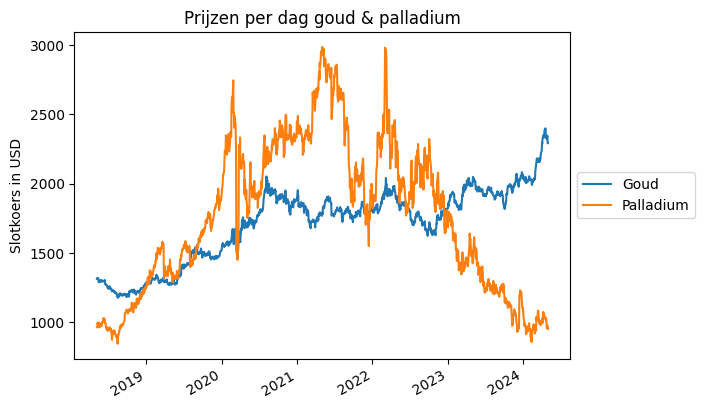

In [ ]:
grondstoffen_plaatje = grondstoffen_compleet.loc[:, ["Goud", "Palladium"]]
grondstoffen_plaatje.plot()
plt.ylabel("Slotkoers in USD") # y-as naam geven
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.title("Prijzen per dag goud & palladium") # Grafiek een naam geven

### Histogram

array([[<Axes: title={'center': 'Graan'}>,
        <Axes: title={'center': 'Koffie'}>,
        <Axes: title={'center': 'Vlees'}>,
        <Axes: title={'center': 'Gas'}>],
       [<Axes: title={'center': 'Kolen'}>,
        <Axes: title={'center': 'Olie'}>,
        <Axes: title={'center': 'Goud'}>,
        <Axes: title={'center': 'Palladium'}>]], dtype=object)

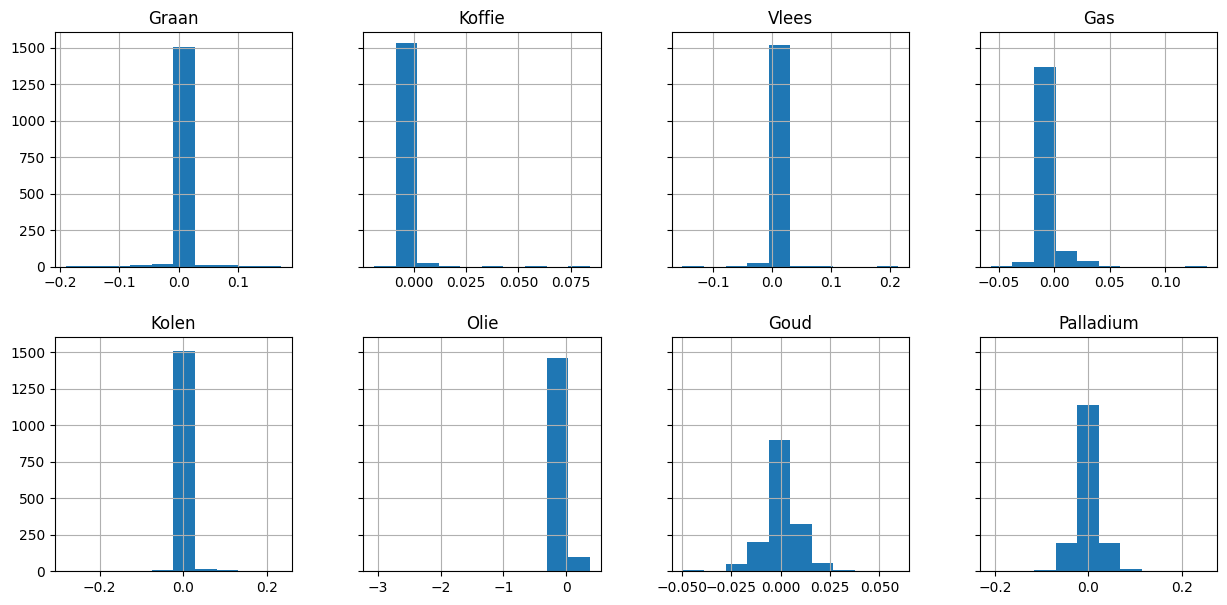

In [ ]:
grondstoffen_compleet_dag.hist(layout=(2, 4), figsize=(15, 7), sharey=True)

### Skewness (of scheefheid)
Geeft aan of de verdeling symmetrisch, links- of rechtsscheef is.
<p>
Als skewness = 0: verdeling is symmetrisch<br>
Als skewness < 0: verdeling is linksscheef, de staarten aan de linkerkant zijn groter / langer dan bij een symmetrische verdeling<br>
Als skewness > 0: verdeling is rechtsscheef, de staarten aan de rechterkant zijn groter / langer dan bij een symmetrische verdeling<br>
<p>
Zie ook: skewness (wikipedia): https://en.wikipedia.org/wiki/Skewness
<p>
In python te berekenen via het commando skew():

In [ ]:
grondstoffen_compleet_dag.skew()

,0
Graan,0.597829
Koffie,19.099680
Vlees,5.106443
Gas,2.405555
Kolen,-0.654895
Olie,-27.158765
Goud,-0.106235
Palladium,0.279652


Conclusie?

### Kurtosis
Geeft aan of de verdeling 'spits' (met veel uitschieters) of 'vlak' (met weinig uitschieters) is.
<p>
Als kurtosis = 0: verdeling is symmetrisch<br>
Als kurtosis =< 3: verdeling heeft weinig uitschieters<br>
Als kurtosis > 3: verdeling heeft veel uitschieters<br>
<p>
Zie ook: kurtosis (wikipedia): https://en.wikipedia.org/wiki/Kurtosis
<p>
In python te berekenen via het commando kurtosis():

In [ ]:
# Calculate kurtosis for all columns
kurtosis_values = grondstoffen_compleet_dag.apply(lambda x: kurtosis(x, nan_policy='omit'))

# Display the results
print(kurtosis_values)

Graan         70.372435
Koffie       455.803186
Vlees        154.024020
Gas           45.272213
Kolen         83.827696
Olie         889.212171
Goud           4.779252
Palladium     10.888855
dtype: float64


Conclusie?

### Boxplot

<Axes: >

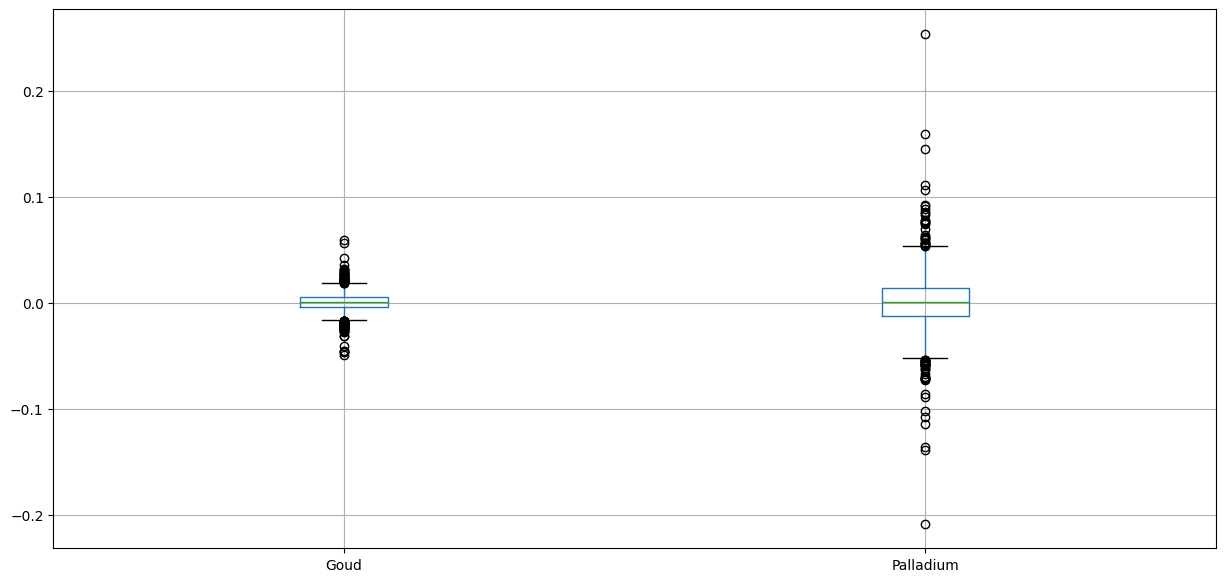

In [ ]:
grondstoffen_compleet_dag.boxplot(column=["Goud", "Palladium"], figsize=(15, 7))

Conclusie?

# Hoe kun je de portfolio- en de grondstoffendata samenvoegen?
Via een concat, join of een merge.

## Concat

In [ ]:
portfolio_compleet = pd.concat([portfolio_gevuld, grondstoffen_compleet], axis=1)
portfolio_compleetgevuld = portfolio_compleet.ffill()
portfolio_compleetgevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,39.726143,48.679867,269.661926,32.033474,28.472565,63.861736,197.858353,76.212563,9119.009766,0.841407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-02,41.481045,48.771523,269.609314,31.062515,28.712614,64.452644,195.668015,76.175385,9235.919922,0.859094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-03,41.556217,49.074661,277.087677,31.350521,28.942226,63.316315,195.132980,76.167976,9743.860352,0.884466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-04,43.186604,49.236824,275.481445,31.753721,29.025728,64.089020,196.412064,76.264488,9700.759766,0.895442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-05,43.186604,49.236824,275.481445,31.753721,29.025728,64.089020,196.412064,76.264488,9858.150391,0.905103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63419.140625,0.517775,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-28,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63113.230469,0.510377,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,171.935226,67.536270,470.439880,134.918091,61.453316,162.538162,412.956268,80.815430,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,168.793823,66.187767,469.288513,133.788071,60.402534,159.899857,409.026184,80.553482,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


Let Op: er zitten nu nog NaN's in de dataset, dat komt omdat we de begindatum van de grondstoffen (7 mei 2018!) niet hebben aangepast.<br>
De laatste stap is dus te filteren op deze begindatum:

In [ ]:
portfolio_compleetgevuld = portfolio_compleetgevuld.loc[portfolio_compleetgevuld.loc[:, "Gas"] > 0, :]
portfolio_compleetgevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,43.499058,49.159275,278.360443,31.638512,28.952671,63.952671,198.301498,76.271973,9373.009766,0.832641,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,43.708145,49.370766,289.016296,32.239197,28.916138,64.861732,198.134262,76.175385,9234.820312,0.813970,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,44.015892,50.555149,287.541656,32.379078,29.516279,66.452576,202.088608,76.064056,9325.179688,0.802043,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,44.645500,50.740887,286.505981,32.724674,29.928541,66.770737,203.518158,76.153122,9043.940430,0.758237,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,44.475693,51.426674,285.531616,32.839867,29.949413,66.361687,203.083450,76.249672,8441.490234,0.684948,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63419.140625,0.517775,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-28,167.773117,67.674812,464.857147,134.723251,60.767635,160.423569,409.850555,80.499298,63113.230469,0.510377,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,171.935226,67.536270,470.439880,134.918091,61.453316,162.538162,412.956268,80.815430,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,168.793823,66.187767,469.288513,133.788071,60.402534,159.899857,409.026184,80.553482,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


## Join

In [ ]:
portfolio_gevuld.join(grondstoffen_compleet)

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
Date,,,,,,,,,,,,,,,,,,
2018-05-01,39.899284,50.634235,273.995361,32.430229,29.978441,64.199776,201.957367,80.236794,9119.009766,0.841407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-02,41.661835,50.729542,273.941803,31.447245,30.231184,64.793793,199.721649,80.197708,9235.919922,0.859094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-03,41.737331,51.044853,281.540344,31.738808,30.472950,63.651455,199.175568,80.189911,9743.860352,0.884466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-04,43.374828,51.213528,279.908295,32.146999,30.560863,64.428230,200.481140,80.291512,9700.759766,0.895442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-05,43.374828,51.213528,279.908295,32.146999,30.560863,64.428230,200.481140,80.291512,9858.150391,0.905103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-26,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63755.320312,0.526112,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-27,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63419.140625,0.517775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-04-28,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63113.230469,0.510377,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Ook bij de join geldt: begindatum is niet aangepast, daarnaast is hier de forward-fill nog niet toegepast.

## Merge

In [ ]:
portfolio_compleet = pd.merge(portfolio_gevuld, grondstoffen_compleet, left_index=True, right_index=True)
portfolio_compleet

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,43.688641,51.132858,282.833527,32.030376,30.483942,64.291130,202.409668,80.299339,9373.009766,0.832641,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,43.898643,51.352875,293.660614,32.638496,30.445469,65.205009,202.238968,80.197708,9234.820312,0.813970,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,44.207741,52.584797,292.162323,32.780109,31.077354,66.804321,206.275223,80.080452,9325.179688,0.802043,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,44.840084,52.777992,291.109894,33.129982,31.511427,67.124146,207.734467,80.174240,9043.940430,0.758237,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,44.669540,53.491302,290.119934,33.246613,31.533400,66.712929,207.290695,80.275902,8441.490234,0.684948,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-24,168.225662,70.257263,466.546600,131.135406,63.887802,158.133652,413.909210,85.035210,64276.898438,0.527404,208.381685,253.486,270.568182,3.668,638.273,82.809998,2324.500000,1007.400024
2024-04-25,169.091583,70.391769,479.808502,134.695618,63.550262,160.189926,410.983704,84.711899,64481.707031,0.525512,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63755.320312,0.526112,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,172.684601,70.247665,477.999634,136.589111,64.703506,163.398499,421.511505,85.082764,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012


Keurig alles gevuld ..  maar we missen alle weekenddata! Oppassen dus met dat samenvoegen!

In [ ]:
portfolio_compleet = pd.merge(portfolio_gevuld, grondstoffen_compleet, how='outer', left_index=True, right_index=True)
portfolio_compleet

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,39.899284,50.634235,273.995361,32.430229,29.978441,64.199776,201.957367,80.236794,9119.009766,0.841407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-02,41.661835,50.729542,273.941803,31.447245,30.231184,64.793793,199.721649,80.197708,9235.919922,0.859094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-03,41.737331,51.044853,281.540344,31.738808,30.472950,63.651455,199.175568,80.189911,9743.860352,0.884466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-04,43.374828,51.213528,279.908295,32.146999,30.560863,64.428230,200.481140,80.291512,9700.759766,0.895442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-05,43.374828,51.213528,279.908295,32.146999,30.560863,64.428230,200.481140,80.291512,9858.150391,0.905103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63419.140625,0.517775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-04-28,168.504349,70.391769,472.327179,136.391876,63.981560,161.272690,418.341400,84.749908,63113.230469,0.510377,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-04-29,172.684601,70.247665,477.999634,136.589111,64.703506,163.398499,421.511505,85.082764,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,169.529495,68.845009,476.829742,135.445099,63.597149,160.746216,417.499939,84.806961,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


Hier gaat het ook nog niet goed .. <br>

Ergo: als we gaan samenvoegen, moeten we eerst de ontbrekende waarden in de kolommen aanvullen met forward_fill. <br>
Kunnen we maandelijkse / wekelijkse data op dagbasis aanvullen? Ja: zie hierboven.

# Data naar Excel exporteren
Als je data naar Excel wilt exporteren, gebruik dan onderstaand commando:

In [ ]:
portfolio_compleetgevuld.to_excel('portfolio.xlsx', index=True)

# Data uit Excel importeren
Als je data uit Excel wilt importeren, gebruik dan onderstaand commando:

In [ ]:
portfolio_excel = pd.read_excel("portfolio.xlsx", sheet_name="portfolio")

portfolio_excel

Let Op: het bestand dat je exporteert of wilt importeren, komt te staan / moet staan in de map ' content':<br>
zie menu helemaal links, klik op het onderste ' Bestanden'-icoontje en kijk in de map ' content'.